# NLP Assignment 1: Training Word2Vec on Child Speech

In this assignment, you will:

1. **Implement** and **Train** a Word2Vec (CBOW) model on a child speech dataset (50%).  
2. **Explore** word similarity using the learned embeddings (code: 20%; discussion: 15%).  
3. **Visualise** embeddings in 2D using SVD (15%).

**We will randomly run 15 submissions. If any bug occurs during execution OR the results fall outside a reasonable reproducible range compared to the logged results, the submission will receive 0 mark for this assignment.**

## 0. Load and clean the text data

In this step, we load the text file `1000_cs.txt` and pre-process each line by:
- Removing punctuation and special characters;
- Removing line breaks;
- Converting all text to lowercase;

The cleaned text is stored in `clean_sentences`, which will be then used to build the vocabulary and data for training the CBOW model.


In [30]:
import re
from collections import Counter

def preprocess(sentence):
    sentence = re.sub('[^A-Za-z0-9]+', ' ', sentence)
    sentence = re.sub('\n', '', sentence)
    sentence = sentence.lower()
    return sentence

sentences = open("1000_cs.txt", "r").readlines()
clean_sentences = [preprocess(sentence) for sentence in sentences]

#print(clean_sentences[0:5])

## 1. Filter out low-frequency tokens

Here, we replace words that appear less than a minimum frequency (default=2) with the special token `<unk>`.  

This helps:
- Reduce vocabulary size
- Deal with unseen words
- Make the training process more stable

The filtered sentences are stored in `filtered_sentences`.

In [29]:
from collections import Counter

def filter_low_freq_tokens(sentences, min_freq=2, unk_token="<unk>"):
    filtered_sentences = []
    all_tokens = " ".join(sentences).split()
    word_counts = Counter(all_tokens)
    for s in sentences:
        toks = s.split()
        toks = [w if word_counts[w] >= min_freq else unk_token for w in toks]
        filtered_sentences.append(" ".join(toks))
    return filtered_sentences

filtered_sentences = filter_low_freq_tokens(clean_sentences, min_freq=2, unk_token="<unk>")

#print(filtered_sentences[0:5])

## 2. Build the CBOW training data

We now build the vocabulary and create training samples for the CBOW model.
- `vocab`: the list of unique words in the corpus  
- `word_to_ix` / `ix_to_word`: mappings between words and their indices  
- For each word in a sentence, we take a fixed-size context window (default=2)
  and use the surrounding words as input and the center word as the target.

Each training sample has the form: `(context_words, target_word)`.
The resulting dataset is stored in `data`.

In [38]:
def build_cbow_data(sentences, window_size=2):
    words = " ".join(sentences).split()
    vocab = set(words)

    word_to_ix = {word: i for i, word in enumerate(vocab)}
    ix_to_word = {i: word for i, word in enumerate(vocab)}

    data = []
    for s in sentences:
        ws = s.split()
        for i in range(window_size, len(ws) - window_size):
            context = [ws[i - j - 1] for j in reversed(range(window_size))] + \
                      [ws[i + j + 1] for j in range(window_size)]
            target = ws[i]
            data.append((context, target))

    return vocab, word_to_ix, ix_to_word, data

vocab, word_to_ix, ix_to_word, data = build_cbow_data(filtered_sentences, window_size=2)

### print(vocab)
### print(word_to_ix)
### print(ix_to_word)

## 3. Implement the CBOW model

To make the training process cleaner and more reusable, we wrap the core functions (`forward`, `backward`, `update`) into a `CBOW` class.

This helps:
- Keep model logic and training logic separate
- Make the code easier to read and maintain
- Allow easy extension (e.g., negative sampling or Skip-gram)

Please complete the functions in the below code based on the pseudo-code in the course slide.

In [69]:
import numpy as np

class CBOW:
    def __init__(self, vocab_size, embed_dim=100, lr=0.01):
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.lr = lr
        self.W_in = np.random.uniform(-0.01, 0.01, (vocab_size, embed_dim)).astype(np.float32)
        self.W_out = np.random.uniform(-0.01, 0.01, (embed_dim, vocab_size)).astype(np.float32)

    def log_softmax(self, x):
        x = x - np.max(x, axis=-1, keepdims=True)
        return x - np.log(np.exp(x).sum(axis=-1, keepdims=True))

    def forward(self, context_idxs):
        # Please write your code here
        # Average relevant rows from W_in, maintain (1,D) dimension
        h = self.W_in[context_idxs].mean(axis=0, keepdims=True)
        logits = np.matmul(h, self.W_out) # context representation * output embeddings
        log_probs = self.log_softmax(logits) #log_softmax(scores)
        return h, logits, log_probs

    def nll_loss(self, log_probs, target_idxs):
        return -log_probs[np.arange(len(target_idxs)), target_idxs].mean()

    def backward(self, preds, target_idxs, context_len):
        # Please write your code here
        h, logits, log_probs = preds
        one_hot = np.zeros(self.vocab_size)
        one_hot[target_idxs[0]] = 1
        dLogits = np.exp(log_probs) - one_hot
        dW_out = np.matmul(np.transpose(h), dLogits)
        dh_each = np.matmul(dLogits, np.transpose(self.W_out)) / context_len
        dh_each = np.repeat(dh_each, context_len)
        return dW_out, dh_each

    def update(self, context_idxs, dW_out, dh_each):
        # Please write your code here
        self.W_out = self.W_out - self.lr * dW_out
        for i, idx in enumerate(context_idxs):
            self.W_in[idx] = self.W_in[idx] - self.lr * dh_each[i]

    def train_one_epoch(self, data):
        losses = []
        for context, target in data:
            context_idxs = np.array([word_to_ix[w] for w in context], dtype=np.int64)
            target_idxs = np.array([word_to_ix[target]], dtype=np.int64)

            preds = self.forward(context_idxs)
            loss = self.nll_loss(preds[-1], target_idxs)
            losses.append(loss)

            dW_out, dh_each = self.backward(preds, target_idxs, len(context_idxs))
            self.update(context_idxs, dW_out, dh_each)
        return np.mean(losses)

## 4. Model Training and Loss Visualisation

We now train the CBOW model for 30 epochs.  
For each epoch, we record the average negative log-likelihood loss and compute the perplexity.
After training, we plot the loss curve to observe the learning trend.

782
Epoch 1/50 | Avg loss: 6.6616 | PPL: 781.82
Epoch 2/50 | Avg loss: 6.6419 | PPL: 766.54
Epoch 3/50 | Avg loss: 6.1298 | PPL: 459.36
Epoch 4/50 | Avg loss: 5.6142 | PPL: 274.30
Epoch 5/50 | Avg loss: 5.4336 | PPL: 228.98
Epoch 6/50 | Avg loss: 5.3583 | PPL: 212.37
Epoch 7/50 | Avg loss: 5.3158 | PPL: 203.54
Epoch 8/50 | Avg loss: 5.2876 | PPL: 197.86
Epoch 9/50 | Avg loss: 5.2669 | PPL: 193.81
Epoch 10/50 | Avg loss: 5.2507 | PPL: 190.70
Epoch 11/50 | Avg loss: 5.2375 | PPL: 188.21
Epoch 12/50 | Avg loss: 5.2264 | PPL: 186.13
Epoch 13/50 | Avg loss: 5.2168 | PPL: 184.34
Epoch 14/50 | Avg loss: 5.2083 | PPL: 182.79
Epoch 15/50 | Avg loss: 5.2008 | PPL: 181.41
Epoch 16/50 | Avg loss: 5.1939 | PPL: 180.17
Epoch 17/50 | Avg loss: 5.1877 | PPL: 179.05
Epoch 18/50 | Avg loss: 5.1819 | PPL: 178.03
Epoch 19/50 | Avg loss: 5.1766 | PPL: 177.08
Epoch 20/50 | Avg loss: 5.1717 | PPL: 176.21
Epoch 21/50 | Avg loss: 5.1671 | PPL: 175.40
Epoch 22/50 | Avg loss: 5.1627 | PPL: 174.64
Epoch 23/50 | A

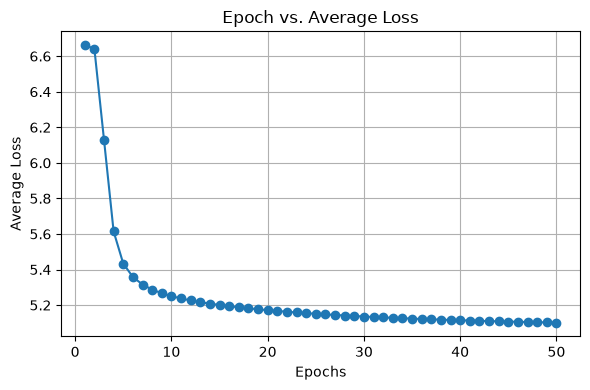

In [72]:
import numpy as np
import matplotlib.pyplot as plt

epoch_num = 50
epoch_losses = [] 

model = CBOW(vocab_size=len(vocab), embed_dim=100, lr=0.02) 

print(len(vocab))

for epoch in range(epoch_num):
    avg_loss = model.train_one_epoch(data)
    ppl = np.exp(avg_loss)
    epoch_losses.append(float(avg_loss))   
    print(f"Epoch {epoch+1}/{epoch_num} | Avg loss: {avg_loss:.4f} | PPL: {ppl:.2f}")

epochs = np.arange(1, epoch_num + 1)

plt.figure(figsize=(6,4))
plt.title('Epoch vs. Average Loss')
plt.plot(epochs, epoch_losses, marker='o')  
plt.xlabel('Epochs')
plt.ylabel('Average Loss')
plt.grid(True)
plt.tight_layout()
plt.show()


## 5. Nearest neighbors (cosine similarity)

We retrieve semantically similar words by nearest neighbors in the embedding space.
Given a word and the `k` parameter, the function `topk_neighbors` will return a list of top k similar words.


In [ ]:
import numpy as np

def topk_neighbors(word, k, model, word_to_ix, ix_to_word):
    # Please write your code here
    return [(ix_to_word[i], float(sims[i])) for i in idx]

words = ['daddy', 'mummy', 'want', 'water', 'cat']
for word in words:
    print(topk_neighbors(word, k=10, model, word_to_ix, ix_to_word))

### Discussion 

Please discuss the results of the similarity calculation with a top_k of 10, using five words: `daddy`, `mummy`, `want`, `water`, `cat` (200 words max).

## 6. Visualise embeddings with SVD (PCA)

We now visualise the high-dimensional word embeddings into a 2D space using Singular Value Decomposition (SVD). 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_embeddings_svd2_simple(
    model,
    ix_to_word,
    max_points=300,
    annotate_k=10,
    random_state=42,
    title="Embeddings SVD (top-2)"
):

    # Please write your code here

    return coords, explained_var, sampled_idx

coords, explained_var, idx = plot_embeddings_svd2(
    ix_to_word=ix_to_word,
    model=model,              
    max_points=300,
    annotate_k=10,
    random_state=42
)